# Task 2: Compound PCFG

From CKY to Neural Grammar Induction · Penn Treebank, Partition A

## Settings

Set `train_compound_model = True` to train Task 2 from scratch. With `False`, the notebook loads the saved model from `model_dir` or downloads it from the project folder.

In [1]:
from pathlib import Path

seed = 42
train_compound_model = False
train_supervised_model = False
download_models = True
model_dir = Path("checkpoints")
results_dir = Path("results")

In [2]:
import hashlib
import importlib.util
import json
import random
import subprocess
import sys
import zipfile
from collections import Counter, defaultdict
from datetime import datetime
from importlib.metadata import version
from math import log

packages = {
    "nltk": "nltk==3.9.1",
    "torch_struct": "torch-struct==0.5",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
}
if download_models:
    packages["gdown"] = "gdown==5.2.0"

missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from nltk.corpus import treebank
from nltk.tree import Tree
from torch import nn
from torch.nn import functional as F
from torch_struct import SentCFG

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

run_dir = results_dir / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
run_dir.mkdir(parents=True)
new_model_dir = run_dir / "trained_checkpoints"
new_model_dir.mkdir()

In [3]:
saved_models = {
    "task2": (
        "task2_best_epoch1_saved.pt",
        "1yDXrNZwlQzL2ifp_vFX9xEn0WlC8G4vL",
        "237073d7409caf1e9093b7db816f6686a9f87c15bf1b9b17c975b39b0fc1c87e",
    ),
    "task3": (
        "task3_epoch15.pt",
        "1TSyhTKk_6pZg8I6Lz2jJtEObzL6RwpCU",
        "73929d6170a1c937798fd628629e495dd11acc4e54f7ed1d709ecf0690d07352",
    ),
}


def file_hash(path):
    with path.open("rb") as file:
        return hashlib.file_digest(file, "sha256").hexdigest()


def checkpoint_path(task):
    filename, drive_id, expected_hash = saved_models[task]
    path = model_dir / filename

    if not path.exists():
        if not download_models:
            raise FileNotFoundError(f"Expected checkpoint at {path}")
        import gdown

        model_dir.mkdir(parents=True, exist_ok=True)
        temporary_file = path.with_suffix(".part")
        try:
            gdown.download(id=drive_id, output=str(temporary_file), use_cookies=False)
            if not temporary_file.exists() or file_hash(temporary_file) != expected_hash:
                raise ValueError(f"The download for {filename} did not match the saved model.")
            temporary_file.replace(path)
        finally:
            temporary_file.unlink(missing_ok=True)

    if download_models and file_hash(path) != expected_hash:
        raise ValueError(f"{path} differs from the shared checkpoint.")
    return path


def save_json(filename, value):
    (run_dir / filename).write_text(json.dumps(value, indent=2, ensure_ascii=False),
                                   encoding="utf-8")


package_names = ["numpy", "nltk", "torch", "torch-struct", "pandas", "matplotlib"]
if download_models:
    package_names.append("gdown")
package_versions = {package: version(package) for package in package_names}
run_info = {
    "seed": seed,
    "device": str(device),
    "python": sys.version.split()[0],
    "packages": package_versions,
    "checkpoints": {},
    "task2_mode": "train" if train_compound_model else "checkpoint",
    "task3_mode": "train" if train_supervised_model else "checkpoint",
    "evaluation": "Unique unlabeled spans after punctuation projection; no full-sentence or single-word spans.",
}


def record_checkpoint(task, path, checkpoint):
    run_info["checkpoints"][task] = {
        "filename": path.name,
        "epoch": checkpoint["epoch"],
        "sha256": file_hash(path),
        "validation_loss": checkpoint.get("best_validation_loss"),
    }

## Data and split

I shuffle the 3,914 trees with seed 42, take the first 1,305 for Partition A, and shuffle that partition again before splitting it. I remove empty categories and strip functional suffixes such as NP-SBJ. The words, case and punctuation stay in the model input.

In [4]:
def clean_tree(node):
    if isinstance(node, str):
        return node
    if node.label() == "-NONE-":
        return None

    children = [clean_tree(child) for child in node]
    children = [child for child in children if child is not None]
    if not children:
        return None

    label = node.label()
    if not label.startswith("-"):
        label = label.split("-", 1)[0].split("=", 1)[0]
    return Tree(label, children)


try:
    all_trees = list(treebank.parsed_sents())
except LookupError:
    nltk.download("treebank", quiet=True)
    all_trees = list(treebank.parsed_sents())

assert len(all_trees) == 3914
indices = np.random.RandomState(seed).permutation(len(all_trees))
partitions = {
    "A": indices[:1305].tolist(),
    "B": indices[1305:2610].tolist(),
    "C": indices[2610:].tolist(),
}
partition_a = np.random.RandomState(seed).permutation(partitions["A"])
train_end = int(0.8 * len(partition_a))
validation_end = train_end + int(0.1 * len(partition_a))
split_indices = {
    "train": partition_a[:train_end].tolist(),
    "validation": partition_a[train_end:validation_end].tolist(),
    "test": partition_a[validation_end:].tolist(),
}
trees_by_split = {
    split: [clean_tree(all_trees[index]) for index in tree_indices]
    for split, tree_indices in split_indices.items()
}
train_trees = trees_by_split["train"]
validation_trees = trees_by_split["validation"]
test_trees = trees_by_split["test"]

save_json("partition_indices.json", {"partitions": partitions, "partition_a_splits": split_indices})
split_text = json.dumps(split_indices, sort_keys=True, separators=(",", ":"))
run_info["split_sha256"] = hashlib.sha256(split_text.encode()).hexdigest()
display(pd.DataFrame([
    {"Split": split.title(), "Trees": len(trees)} for split, trees in trees_by_split.items()
]))

,Split,Trees
0,Train,1044
1,Validation,130
2,Test,131


In [5]:
def replace_rare_words(trees, cutoff):
    word_counts = Counter(word for tree in trees for word in tree.leaves())
    changed_trees = []
    for tree in trees:
        changed = tree.copy(deep=True)
        for position in changed.treepositions("leaves"):
            if word_counts[changed[position]] <= cutoff:
                changed[position] = "<UNK>"
        changed_trees.append(changed)
    return changed_trees


def to_cnf(tree, markov_order):
    binary_tree = tree.copy(deep=True)
    binary_tree.collapse_unary(collapsePOS=True, collapseRoot=True)
    binary_tree.chomsky_normal_form(factor="right", horzMarkov=markov_order)
    return binary_tree

## How I score the parses

A bracket records where a phrase starts and ends. Labeled F1 also checks its category, such as NP. The original Task 1 scores keep punctuation. For the comparison across all three tasks, I remove punctuation using the gold POS tags, count each remaining span once, and exclude single words and the full sentence. A sentence with fewer than two content words is skipped. A failed parse on an eligible sentence still counts against recall.

In [6]:
punctuation_tags = {".", ",", ":", "``", "''", "-LRB-", "-RRB-"}


def brackets(tree, labeled=False):
    spans = Counter()

    def visit(node, start, is_root=False):
        if isinstance(node, str):
            return start + 1
        end = start
        for child in node:
            end = visit(child, end)
        if not is_root and any(isinstance(child, Tree) for child in node):
            span = (start, end, node.label()) if labeled else (start, end)
            spans[span] += 1
        return end

    if tree is not None:
        visit(tree, 0, is_root=True)
    return spans


def content_length(tree):
    return sum(tag not in punctuation_tags for _, tag in tree.pos())


def project_spans(spans, prefix):
    # prefix[i] counts the content words before original position i.
    projected = set()
    for start, end in spans:
        left, right = prefix[start], prefix[end]
        if 2 <= right - left < prefix[-1]:
            projected.add((left, right))
    return projected


def score_sentence(split, index, gold_tree, prediction, predicted_spans=None, one_sided=None):
    words = gold_tree.leaves()
    gold_tags = gold_tree.pos()
    prefix = [0]
    for _, tag in gold_tags:
        prefix.append(prefix[-1] + int(tag not in punctuation_tags))

    eligible = prefix[-1] >= 2
    if prediction is not None:
        assert prediction.leaves() == words

    gold = project_spans(brackets(gold_tree), prefix)
    predicted = project_spans(
        brackets(prediction) if predicted_spans is None else predicted_spans, prefix
    )
    matches = gold & predicted
    span_count = len(gold) + len(predicted)
    sentence_f1 = 2 * len(matches) / span_count if span_count else 1.0

    return {
        "position": index, "corpus_index": split_indices[split][index],
        "tokens": words,
        "scored_words": [word for word, tag in gold_tags if tag not in punctuation_tags],
        "eligible": eligible, "complete": prediction is not None, "one_sided": one_sided,
        "matching": len(matches), "predicted_count": len(predicted), "gold_count": len(gold),
        "sentence_f1": sentence_f1 if eligible else None,
        "gold_spans": sorted(gold), "predicted_spans": sorted(predicted),
        "matching_spans": sorted(matches),
        "extra_spans": sorted(predicted - gold), "missed_spans": sorted(gold - predicted),
        "gold_tree": gold_tree.pformat(margin=10**9),
        "predicted_tree": prediction.pformat(margin=10**9) if prediction is not None else None,
    }


def bracket_scores(matches, predicted, gold):
    precision = matches / predicted if predicted else 0.0
    recall = matches / gold if gold else 0.0
    f1 = 2 * matches / (predicted + gold) if predicted + gold else 0.0
    return precision, recall, f1


def save_evaluation(name, records):
    scored = [row for row in records if row["eligible"]]
    matches = sum(row["matching"] for row in scored)
    predicted = sum(row["predicted_count"] for row in scored)
    gold = sum(row["gold_count"] for row in scored)
    precision, recall, corpus_f1 = bracket_scores(matches, predicted, gold)
    diagnosed = [row["one_sided"] for row in scored if row["one_sided"] is not None]
    summary = {
        "sentences": len(records), "scored": len(scored),
        "skipped": len(records) - len(scored),
        "complete": sum(row["complete"] for row in scored),
        "matching_spans": matches, "predicted_spans": predicted, "gold_spans": gold,
        "precision": precision, "recall": recall, "corpus_f1": corpus_f1,
        "sentence_f1": sum(row["sentence_f1"] for row in scored) / len(scored),
        "one_sided": sum(diagnosed), "long_sentences_diagnosed": len(diagnosed),
    }
    save_json(f"{name}_metrics.json", summary)
    with (run_dir / f"{name}_predictions.jsonl").open("w", encoding="utf-8") as file:
        for row in records:
            file.write(json.dumps(row, ensure_ascii=False) + "\n")
    return summary


def score_row(name, result):
    return {
        "Model": name,
        "Scored": result["scored"],
        "Complete parses": result["complete"],
        "Precision (%)": 100 * result["precision"],
        "Recall (%)": 100 * result["recall"],
        "Sentence F1 (%)": 100 * result["sentence_f1"],
        "Corpus F1 (%)": 100 * result["corpus_f1"],
    }


def show_examples(records, task):
    examples = [row for row in records if row["eligible"] and row["gold_count"]
                and 5 <= len(row["tokens"]) <= 25]
    if len(examples) < 2:
        return
    better = max(examples, key=lambda row: row["sentence_f1"])
    worse = min((row for row in examples if row is not better),
                key=lambda row: row["sentence_f1"])

    for name, row in [("High F1", better), ("Low F1", worse)]:
        print(f"{name} · test sentence {row['position']} · F1 {row['sentence_f1']:.1%}")
        print(" ".join(row["tokens"]))
        print("Gold:     ", Tree.fromstring(row["gold_tree"]).pformat(margin=95))
        predicted = row["predicted_tree"]
        print("Predicted:", Tree.fromstring(predicted).pformat(margin=95) if predicted else "No parse")
        words = row["scored_words"]
        for label, key in [("Matched", "matching_spans"), ("Missed", "missed_spans"),
                           ("Extra", "extra_spans")]:
            phrases = [" ".join(words[i:j]) for i, j in row[key]]
            print(f"{label}: {', '.join(phrases) or '—'}")
        print()

    save_json(f"{task}_examples.json", [better, worse])

## Task 2: Compound PCFG

This model sees only the words during training. A bidirectional LSTM turns each sentence into a 64-dimensional latent vector z, and the grammar predicts rule probabilities conditioned on z. I leave out the one single-token training sentence because the binary inside calculation needs at least two words. Batching sentences of equal length avoids padding.

In [7]:
def encode_words(words, vocabulary):
    return [vocabulary.get(word, vocabulary["<UNK>"]) for word in words]


def length_batches(sentences, batch_size=4):
    by_length = defaultdict(list)
    for sentence in sentences:
        by_length[len(sentence)].append(sentence)
    batches = []
    for length in sorted(by_length):
        group = by_length[length]
        for start in range(0, len(group), batch_size):
            batches.append(torch.tensor(group[start:start + batch_size], dtype=torch.long))
    return batches


training_sentences = [tree.leaves() for tree in train_trees if len(tree.leaves()) >= 2]
word_counts = Counter(word for sentence in training_sentences for word in sentence)
ranked_words = sorted(word_counts, key=lambda word: (-word_counts[word], word))
compound_vocab = {"<UNK>": 0}
for word in ranked_words[:4000]:
    compound_vocab[word] = len(compound_vocab)

train_batches = length_batches([encode_words(words, compound_vocab) for words in training_sentences])
validation_batches = length_batches([
    encode_words(tree.leaves(), compound_vocab) for tree in validation_trees
])
print(f"{len(training_sentences):,} training sentences, {len(compound_vocab):,} word IDs.")

1,043 training sentences, 4,001 word IDs.


### Encoder and rule probabilities

The encoder predicts a mean and log variance for z. The grammar uses three MLPs: one for root labels, one for pairs of child labels, and one for word emissions. NT means nonterminal; PT means preterminal, the label directly above a word.

In [8]:
def rule_mlp(input_size, output_size):
    return nn.Sequential(nn.Linear(input_size, 256), nn.ReLU(), nn.Linear(256, output_size))


class SentenceEncoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 256)
        self.bilstm = nn.LSTM(256, 256, num_layers=1, bidirectional=True, batch_first=True)
        self.to_params = nn.Linear(512, 128)

    def forward(self, word_ids):
        word_vectors = self.embedding(word_ids)
        hidden_states, _ = self.bilstm(word_vectors)
        sentence_vector = hidden_states.max(dim=1).values
        return self.to_params(sentence_vector).chunk(2, dim=-1)


class CompoundGrammar(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.num_nt = 30
        self.num_pt = 60
        self.num_symbols = self.num_nt + self.num_pt
        self.root_embedding = nn.Parameter(torch.randn(256) * 0.02)
        self.nt_embedding = nn.Embedding(self.num_nt, 256)
        self.pt_embedding = nn.Embedding(self.num_pt, 256)

        self.root_mlp = rule_mlp(256 + 64, self.num_nt)
        self.rule_mlp = rule_mlp(256 + 64, self.num_symbols ** 2)
        self.word_mlp = rule_mlp(256 + 64, vocab_size)

    def forward(self, z):
        batch_size = z.size(0)
        root_input = torch.cat([self.root_embedding.expand(batch_size, -1), z], dim=-1)
        root_scores = F.log_softmax(self.root_mlp(root_input), dim=-1)

        nt = self.nt_embedding.weight.unsqueeze(0).expand(batch_size, -1, -1)
        nt_input = torch.cat([nt, z.unsqueeze(1).expand(-1, self.num_nt, -1)], dim=-1)
        rule_scores = F.log_softmax(self.rule_mlp(nt_input), dim=-1)
        rule_scores = rule_scores.view(batch_size, self.num_nt, self.num_symbols, self.num_symbols)

        pt = self.pt_embedding.weight.unsqueeze(0).expand(batch_size, -1, -1)
        pt_input = torch.cat([pt, z.unsqueeze(1).expand(-1, self.num_pt, -1)], dim=-1)
        word_scores = F.log_softmax(self.word_mlp(pt_input), dim=-1)
        return root_scores, rule_scores, word_scores


torch.manual_seed(seed)
encoder = SentenceEncoder(len(compound_vocab)).to(device)
compound_grammar = CompoundGrammar(len(compound_vocab)).to(device)

### Training objective

The inside algorithm sums the probabilities of all possible trees for the sentence. I minimize the negative log of that sum plus the KL penalty for z. When training a fresh model, I keep the checkpoint with the lowest validation loss.

In [9]:
def sentence_distribution(word_ids, z):
    root_scores, rule_scores, word_scores = compound_grammar(z)
    # For each preterminal, select the scores of the words in the input.
    word_indices = word_ids.unsqueeze(1).expand(-1, word_scores.size(1), -1)
    emissions = word_scores.gather(2, word_indices).transpose(1, 2).contiguous()
    return SentCFG((emissions, rule_scores, root_scores))


def compound_loss(word_ids):
    mean, log_variance = encoder(word_ids)
    std = torch.exp(0.5 * log_variance)
    z = mean + torch.randn_like(std) * std
    negative_log_likelihood = -sentence_distribution(word_ids, z).partition
    kl = -0.5 * (1 + log_variance - mean.square() - log_variance.exp()).sum(dim=1)
    return negative_log_likelihood + kl


@torch.no_grad()
def compound_validation_loss():
    encoder.eval()
    compound_grammar.eval()
    loss_sum = sentence_count = 0
    gpu_devices = [torch.cuda.current_device()] if device.type == "cuda" else []
    with torch.random.fork_rng(devices=gpu_devices):
        # Use the same noise samples when comparing epochs.
        torch.manual_seed(1234)
        for batch in validation_batches:
            loss_sum += compound_loss(batch.to(device)).sum().item()
            sentence_count += len(batch)
    return loss_sum / sentence_count


def train_compound(epochs=15):
    parameters = list(encoder.parameters()) + list(compound_grammar.parameters())
    optimizer = torch.optim.Adam(parameters, lr=1e-3, betas=(0.75, 0.999))
    best_loss = float("inf")
    best_path = new_model_dir / "task2_best.pt"
    history = []

    for epoch in range(1, epochs + 1):
        encoder.train()
        compound_grammar.train()
        batch_order = list(range(len(train_batches)))
        random.Random(seed + epoch).shuffle(batch_order)
        loss_sum = sentence_count = 0

        for batch_index in batch_order:
            batch = train_batches[batch_index].to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = compound_loss(batch).mean()
            if not torch.isfinite(loss):
                raise ValueError(f"Invalid Task 2 loss in epoch {epoch}")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(parameters, 3.0)
            optimizer.step()

            loss_sum += loss.item() * len(batch)
            sentence_count += len(batch)

        train_loss = loss_sum / sentence_count
        validation_loss = compound_validation_loss()
        improved = validation_loss < best_loss
        if improved:
            best_loss = validation_loss
        checkpoint = {
            "epoch": epoch, "encoder": encoder.state_dict(),
            "grammar": compound_grammar.state_dict(), "optimizer": optimizer.state_dict(),
            "vocab": compound_vocab, "best_validation_loss": best_loss,
        }
        torch.save(checkpoint, new_model_dir / "task2_latest.pt")
        if improved:
            torch.save(checkpoint, best_path)
        history.append({"Epoch": epoch, "Train": train_loss, "Validation": validation_loss})
        print(f"Epoch {epoch:2d}: train {train_loss:.3f}, validation {validation_loss:.3f}")

    loss_table = pd.DataFrame(history)
    loss_table.to_csv(run_dir / "task2_training_loss.csv", index=False)
    ax = loss_table.plot(x="Epoch", marker="o", ylabel="Negative ELBO", title="Task 2 training loss")
    ax.figure.tight_layout()
    ax.figure.savefig(run_dir / "task2_training_loss.png", dpi=160)
    plt.show()
    return best_path

In [10]:
task2_path = train_compound() if train_compound_model else checkpoint_path("task2")
checkpoint = torch.load(task2_path, map_location="cpu", weights_only=True)
if checkpoint["vocab"] != compound_vocab:
    raise ValueError("Task 2 checkpoint uses different word IDs.")
encoder.load_state_dict(checkpoint["encoder"])
compound_grammar.load_state_dict(checkpoint["grammar"])
encoder.eval()
compound_grammar.eval()
record_checkpoint("task2", task2_path, checkpoint)
print(f"Task 2 checkpoint: {task2_path.name}, epoch {checkpoint['epoch']}")
del checkpoint

Task 2 checkpoint: task2_best_epoch1_saved.pt, epoch 1


### Choose the decoder on validation

Viterbi returns the most probable tree. Minimum Bayes risk (MBR) uses the posterior probability of each bracket and chooses a tree whose brackets have the highest total probability. Both use the encoder mean for z at test time.

In [11]:
@torch.no_grad()
def decode_distribution(sentence_ids):
    word_ids = torch.tensor([sentence_ids], dtype=torch.long, device=device)
    mean, _ = encoder(word_ids)
    return sentence_distribution(word_ids, mean)


def viterbi_spans(sentence_ids):
    with torch.enable_grad():
        span_mask = decode_distribution(sentence_ids).argmax[3][0].detach()

    n = len(sentence_ids)
    spans = Counter()
    for width_index, start, _ in (span_mask > 0.5).nonzero(as_tuple=False).tolist():
        end = start + width_index + 2
        if (start, end) != (0, n):
            spans[start, end] += 1
    return spans


def mbr_spans(sentence_ids):
    with torch.enable_grad():
        marginals = decode_distribution(sentence_ids).marginals[3][0]
    # Sum over labels; Task 2 evaluates unlabeled spans.
    span_scores = marginals.sum(dim=-1).detach().cpu()

    n = len(sentence_ids)
    best = [[0.0] * (n + 1) for _ in range(n + 1)]
    splits = [[None] * (n + 1) for _ in range(n + 1)]
    for width in range(2, n + 1):
        for start in range(n - width + 1):
            end = start + width
            split = max(range(start + 1, end), key=lambda k: best[start][k] + best[k][end])
            reward = 0.0 if width == n else span_scores[width - 2, start].item()
            best[start][end] = best[start][split] + best[split][end] + reward
            splits[start][end] = split

    spans = Counter()

    def collect(start, end):
        if end - start < 2:
            return
        if (start, end) != (0, n):
            spans[start, end] += 1
        split = splits[start][end]
        collect(start, split)
        collect(split, end)

    collect(0, n)
    return spans


def unlabeled_tree(words, spans):
    # X and W are display labels for internal nodes and words.
    spans = set(spans)

    def build(start, end):
        if end - start == 1:
            return Tree("W", [words[start]])
        for split in range(start + 1, end):
            left_ok = split == start + 1 or (start, split) in spans
            right_ok = end == split + 1 or (split, end) in spans
            if left_ok and right_ok:
                return Tree("X", [build(start, split), build(split, end)])
        raise ValueError(f"Cannot rebuild span {(start, end)}")

    return build(0, len(words))


def evaluate_compound(split, decoder_name, decode):
    records = []
    for index, gold in enumerate(trees_by_split[split]):
        words = gold.leaves()
        if content_length(gold) < 2:
            records.append(score_sentence(split, index, gold, None))
            continue

        spans = decode(encode_words(words, compound_vocab))
        prediction = unlabeled_tree(words, spans)
        one_sided = None
        if len(words) >= 8:
            right_ends = Counter()
            for (_, end), count in spans.items():
                right_ends[end] += count
            one_sided = max(right_ends.values()) / sum(right_ends.values()) >= 0.8
        records.append(score_sentence(split, index, gold, prediction, spans, one_sided))

    result = save_evaluation(f"task2_{split}_{decoder_name.lower()}", records)
    return result, records

Selected on validation sentence F1: MBR


,Decoder,Scored,Complete parses,Precision (%),Recall (%),Sentence F1 (%),Corpus F1 (%)
0,Viterbi,130,130,28.80,39.17,36.95,33.19
1,MBR,130,130,30.46,41.43,38.94,35.11


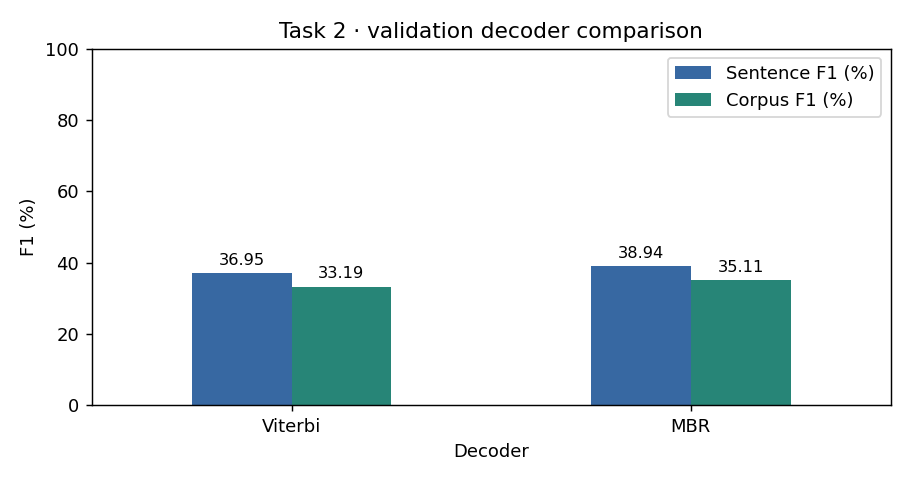

In [12]:
decoders = {"Viterbi": viterbi_spans, "MBR": mbr_spans}
task2_validation = {}
for name, decode in decoders.items():
    task2_validation[name], _ = evaluate_compound("validation", name, decode)

chosen_decoder = max(task2_validation, key=lambda name: task2_validation[name]["sentence_f1"])
decoder_table = pd.DataFrame([
    score_row(name, result) for name, result in task2_validation.items()
]).rename(columns={"Model": "Decoder"})
display(decoder_table.round(2))
print("Selected on validation sentence F1:", chosen_decoder)

ax = decoder_table.set_index("Decoder")[["Sentence F1 (%)", "Corpus F1 (%)"]].plot.bar(
    color=["#3768a2", "#278577"], rot=0, figsize=(7, 3.7), ylim=(0, 100),
    ylabel="F1 (%)", title="Task 2 · validation decoder comparison",
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.legend(loc="upper right")
ax.figure.tight_layout()
ax.figure.savefig(run_dir / "task2_validation_decoders.png", dpi=160)
plt.show()

### Test result and paper comparison

The paper scores models on the standard WSJ split. I use the assigned Partition A and one checkpoint, so the paper values give context for the gap.

In [13]:
task2_test, task2_records = evaluate_compound("test", chosen_decoder, decoders[chosen_decoder])
paper_comparison = {
    "paper_sentence_f1": 0.552, "paper_corpus_f1": 0.524,
    "our_sentence_f1": task2_test["sentence_f1"], "our_corpus_f1": task2_test["corpus_f1"],
    "sentence_gap_percentage_points": 100 * (0.552 - task2_test["sentence_f1"]),
    "corpus_gap_percentage_points": 100 * (0.524 - task2_test["corpus_f1"]),
}
save_json("task2_paper_comparison.json", paper_comparison)
display(pd.DataFrame([
    {"Setting": f"Partition A ({chosen_decoder})",
     "Sentence F1 (%)": 100 * task2_test["sentence_f1"],
     "Corpus F1 (%)": 100 * task2_test["corpus_f1"]},
    {"Setting": "Kim et al. · WSJ-Full", "Sentence F1 (%)": 55.2, "Corpus F1 (%)": 52.4},
]).round(2))

print(f"Test sentences scored: {task2_test['scored']}; skipped: {task2_test['skipped']}")
print("Long test parses with at least 80% of spans sharing a right endpoint:",
      f"{task2_test['one_sided']}/{task2_test['long_sentences_diagnosed']}")
show_examples(task2_records, "task2")

Test sentences scored: 130; skipped: 1
Long test parses with at least 80% of spans sharing a right endpoint: 86/124
High F1 · test sentence 26 · F1 100.0%
`` One says he 's for banning cop-killer bullets .
Gold:      (S
  (`` ``)
  (NP (NN One))
  (VP
    (VBZ says)
    (SBAR
      (S
        (NP (PRP he))
        (VP (VBZ 's) (PP (IN for) (S (VP (VBG banning) (NP (JJ cop-killer) (NNS bullets)))))))))
  (. .))
Predicted: (X
  (X
    (W ``)
    (X
      (W One)
      (X
        (W says)
        (X (W he) (X (W 's) (X (W for) (X (W banning) (X (W cop-killer) (W bullets)))))))))
  (W .))
Matched: says he 's for banning cop-killer bullets, he 's for banning cop-killer bullets, 's for banning cop-killer bullets, for banning cop-killer bullets, banning cop-killer bullets, cop-killer bullets
Missed: —
Extra: —

Low F1 · test sentence 4 · F1 0.0%
`` The record of companies that have diversified is n't all that impressive , '' he says .
Gold:      (S
  (S
    (`` ``)
    (NP
      (NP (DT The) 

,Setting,Sentence F1 (%),Corpus F1 (%)
0,Partition A (MBR),40.49,36.85
1,Kim et al. · WSJ-Full,55.20,52.40


[Kim, Dyer and Rush (2019), Compound Probabilistic Context-Free Grammars for Grammar Induction](https://aclanthology.org/P19-1228/)

In [14]:
run_info["task2_decoder"] = chosen_decoder

In [15]:
run_info.pop("task3_mode", None)
save_json("run_manifest.json", run_info)
(run_dir / "requirements_runtime.txt").write_text(
    "\n".join(f"{name}=={number}" for name, number in package_versions.items()) + "\n"
)
print(f"Results: {run_dir.resolve()}")

Results: /workspace/scratch/f479fa55acc2/submission_work/checks/task2/execution/results/20261107_125947_812244
